In [3]:
import torch
from torch import nn
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [52]:
bias = 0.3
weight = 0.7
START = 0
END = 10
STEP = 0.1
X = torch.arange(START, END, STEP).unsqueeze(dim=1)
y = X * bias + weight
X.shape, y.shape


(torch.Size([100, 1]), torch.Size([100, 1]))

In [18]:
split_size = 0.8
train_test_split = int(len(X) * split_size)

X_train = X[:train_test_split]
X_test = X[train_test_split:]
y_train = y[:train_test_split]
y_test = y[train_test_split:]
len(X_train), len(X_test), len(y_train), len(y_test)

(80, 20, 80, 20)

In [20]:
class SimpleLinearLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.bias = nn.Parameter(torch.randn(1, dtype = torch.float), requires_grad = True)
        self.weight = nn.Parameter(torch.randn(1, dtype = torch.float), requires_grad = True)
    def forward(self, x):
        return self.bias * x + self.weight

model0 = SimpleLinearLayer()
model0.state_dict()

OrderedDict([('bias', tensor([-1.5527])), ('weight', tensor([0.4455]))])

In [22]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(model0.parameters(), lr = 0.01)
epoch_value_count = []
train_loss = []
test_loss = []
epochs = 100

for epoch in range(epochs):
    y_pred_train = model0(X_train)
    loss = loss_fn(y_pred_train, y_train)

    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    model0.eval()
    with torch.inference_mode():
        y_pred_test = model0(X_test)
        test_loss_value = loss_fn(y_pred_test, y_test)
    if epoch % 10 == 0:
        epoch_value_count.append(epoch)
        train_loss.append(loss.detach().numpy())
        test_loss.append(test_loss_value.detach().numpy())
        print(f'Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss_value}')
        
        

Epoch: 0 | Loss: 7.572627067565918 | Test Loss: 16.472585678100586
Epoch: 10 | Loss: 5.91237735748291 | Test Loss: 12.837333679199219
Epoch: 20 | Loss: 4.252127647399902 | Test Loss: 9.2020845413208
Epoch: 30 | Loss: 2.5939910411834717 | Test Loss: 5.568084716796875
Epoch: 40 | Loss: 0.9519357681274414 | Test Loss: 1.9495084285736084
Epoch: 50 | Loss: 0.09562648832798004 | Test Loss: 0.042716849595308304
Epoch: 60 | Loss: 0.12753085792064667 | Test Loss: 0.07304531335830688
Epoch: 70 | Loss: 0.12139260768890381 | Test Loss: 0.030721282586455345
Epoch: 80 | Loss: 0.1074533462524414 | Test Loss: 0.021525025367736816
Epoch: 90 | Loss: 0.10631559044122696 | Test Loss: 0.048762835562229156


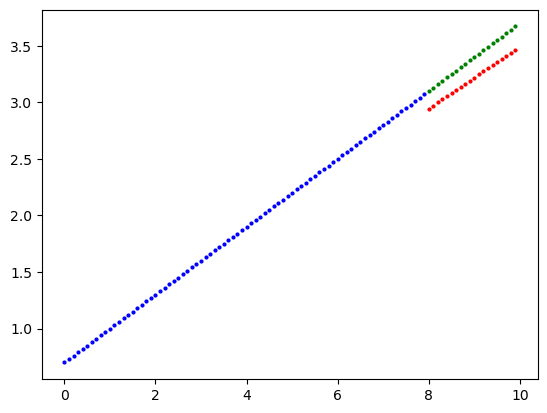

In [28]:
import matplotlib.pyplot as plt
def plot_predictions(X_train = X_train, y_train = y_train, X_test = X_test, predictions = None):
    plt.scatter(X_train, y_train, color = 'b', s=4, label = 'training')
    plt.scatter(X_test, y_test, color = 'g', s=4, label = 'testing')

    if predictions is not None:
        plt.scatter(X_test, predictions, color = 'r', s=4, label = 'Predictions')
torch.manual_seed(42)
model0.eval()
with torch.inference_mode():
    y_preds = model0(X_test)

plot_predictions(predictions = y_preds)

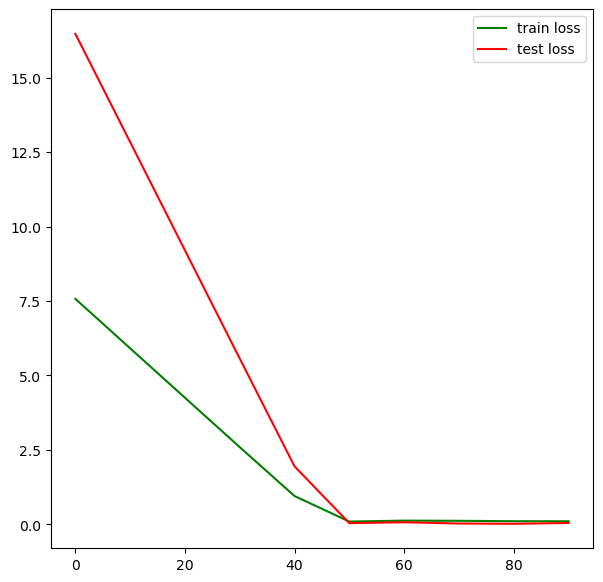

In [32]:
plt.figure(figsize = (7,7))
plt.plot(epoch_value_count, train_loss, color = 'green', label = 'train loss')
plt.plot(epoch_value_count, test_loss, color = 'red', label = 'test loss')
plt.legend()
plt.show()

In [34]:
class Linear_layer(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer = nn.Linear(in_features = 1, out_features = 1)
    def forward(self, x):
        return self.linear_layer(x)

model1 = Linear_layer()
model1

Linear_layer(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)

In [44]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(model1.parameters(), lr = 0.01)
epochs = 200
for epoch in range(epochs):
    model1.train()
    y_pred_train = model1(X_train)
    loss = loss_fn(y_pred_train, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model1.eval()
    with torch.inference_mode():
        y_preds = model1(X_test)
        test_loss = loss_fn(y_preds, y_test)
    if epoch % 50 == 0:
        print(f'epoch is {epoch} | train loss is {loss} | test loss is {test_loss}')

epoch is 0 | train loss is 0.047489289194345474 | test loss is 0.2562286853790283
epoch is 50 | train loss is 0.047489289194345474 | test loss is 0.2562286853790283
epoch is 100 | train loss is 0.047489289194345474 | test loss is 0.2562286853790283
epoch is 150 | train loss is 0.047489289194345474 | test loss is 0.2562286853790283


In [46]:
model1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.2880]])),
             ('linear_layer.bias', tensor([0.6998]))])

In [40]:
model0.state_dict()

OrderedDict([('bias', tensor([0.2748])), ('weight', tensor([0.7448]))])

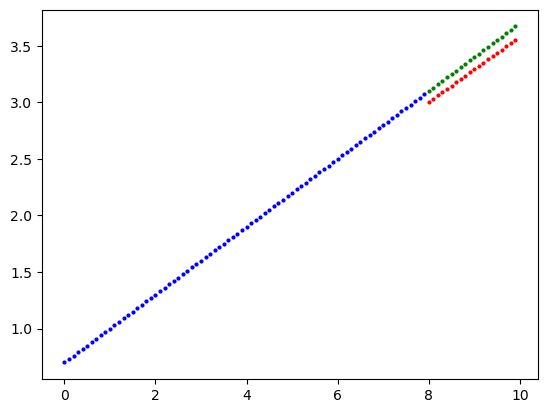

In [48]:
model1.eval()
with torch.inference_mode():
    y_preds = model1(X_test)
plot_predictions(predictions = y_preds)

In [11]:
from sklearn.datasets import make_circles
n_samples = 1000
X,y = make_circles(n_samples = n_samples, noise = 0.02, random_state = 42)
X.shape, y.shape

((1000, 2), (1000,))

In [13]:
import torch
X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)
len(X_train), len(X_test), len(y_train), len(y_test)

(800, 200, 800, 200)

2

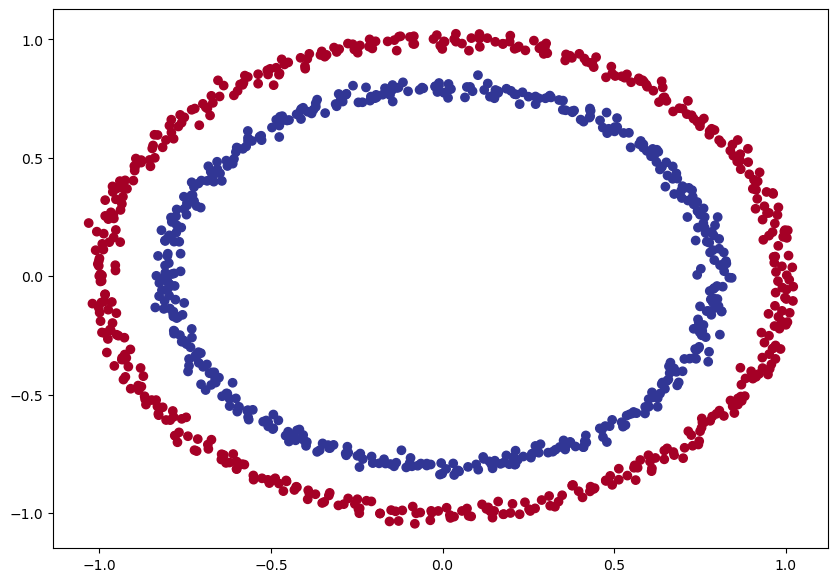

In [66]:
plt.figure(figsize = (10,7))
plt.scatter(X[:,0], X[:, 1], c=y, cmap = plt.cm.RdYlBu)
plt.show()

In [88]:
import requests
from pathlib import Path 

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


In [90]:
class CircleModelV0(nn.Module):
    def __init__(self, input_features: int, output_features: int, hidden_units: int):
        super().__init__()
        self.linear_stack = nn.Sequential(
            nn.Linear(in_features = input_features, out_features = hidden_units),
            nn.ReLU(),
            nn.Linear(in_features = hidden_units, out_features = hidden_units),
            nn.ReLU(),
            nn.Linear(in_features = hidden_units, out_features = output_features)
        )
    def forward(self, x):
        return self.linear_stack(x)
model2 = CircleModelV0(input_features = 2, output_features = 1, hidden_units = 8)
model2

CircleModelV0(
  (linear_stack): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)

In [92]:
from tqdm.auto import tqdm
torch.manual_seed(42)
loss_fn = nn.BCEWithLogitsLoss() 
optimizer = torch.optim.SGD(params = model2.parameters(), lr = 0.1)
epochs = 1000
for epoch in tqdm(range(epochs)):
    model2.train()
    y_pred_train = model2(X_train).squeeze()
    loss = loss_fn(y_pred_train, y_train)
    pred = torch.round(torch.sigmoid(y_pred_train))
    acc = (pred == y_train).sum().item()/len(pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model2.eval()
    with torch.inference_mode():
        y_pred_test = model2(X_test).squeeze()
        test_loss = loss_fn(y_pred_test, y_test)
        test_pred = torch.round(torch.sigmoid(y_pred_test))
        test_acc = (test_pred == y_test).sum().item()/len(test_pred)
    if epoch % 100 == 0:
        print(f'epoch {epoch} | train_loss {loss} | test_loss {test_loss} | train_acc {acc*100}% | test_acc {test_acc*100}%')

  0%|          | 0/1000 [00:00<?, ?it/s]

epoch 0 | train_loss 0.6926620602607727 | test_loss 0.6899000406265259 | train_acc 50.0% | test_acc 50.0%
epoch 100 | train_loss 0.6904258728027344 | test_loss 0.6874855160713196 | train_acc 50.875% | test_acc 56.00000000000001%
epoch 200 | train_loss 0.6888852119445801 | test_loss 0.6854697465896606 | train_acc 51.5% | test_acc 56.49999999999999%
epoch 300 | train_loss 0.6868728399276733 | test_loss 0.6829348206520081 | train_acc 51.87500000000001% | test_acc 56.00000000000001%
epoch 400 | train_loss 0.684041440486908 | test_loss 0.6795883178710938 | train_acc 52.5% | test_acc 56.00000000000001%
epoch 500 | train_loss 0.6797464489936829 | test_loss 0.6748565435409546 | train_acc 53.87499999999999% | test_acc 56.49999999999999%
epoch 600 | train_loss 0.6727504134178162 | test_loss 0.6676089763641357 | train_acc 59.75% | test_acc 61.0%
epoch 700 | train_loss 0.6611729264259338 | test_loss 0.6566810607910156 | train_acc 71.875% | test_acc 74.5%
epoch 800 | train_loss 0.639985978603363 | 

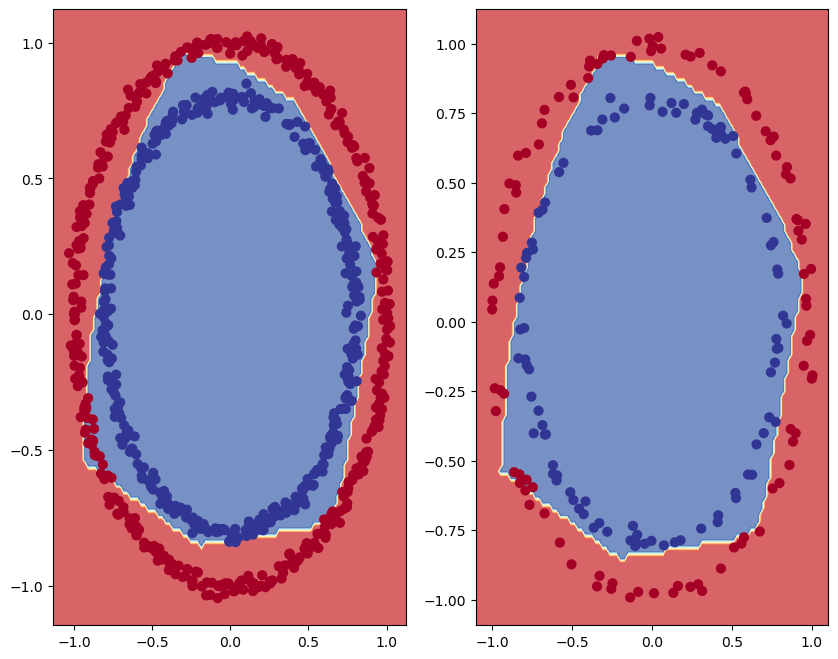

In [94]:
import matplotlib.pyplot as plt
plt.figure(figsize = (10,8))
plt.subplot(1,2,1)
plot_decision_boundary(model2, X_train, y_train)
plt.subplot(1,2,2)
plot_decision_boundary(model2, X_test, y_test)


In [ ]:
model2.state_dict()

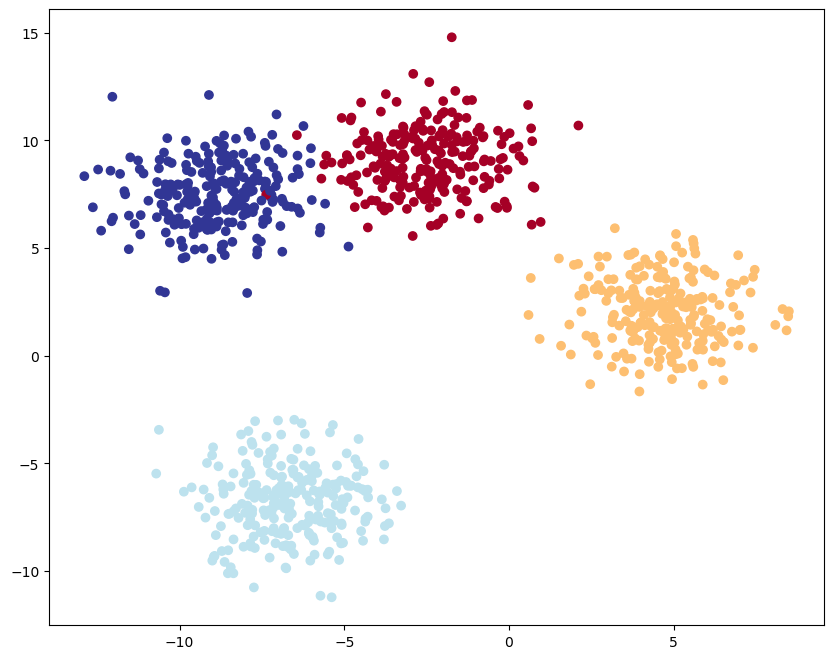

In [76]:
from sklearn.datasets import make_blobs
NUM_FEATURES = 2
NUM_SAMPLES = 1000
NUM_CLASSES = 4
RANDOM_SEED = 42
X_blob, y_blob = make_blobs(n_samples = NUM_SAMPLES, n_features = NUM_FEATURES, centers= NUM_CLASSES, cluster_std=1.5, random_state=RANDOM_SEED)
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob, y_blob, test_size = 0.2, random_state=RANDOM_SEED)
plt.figure(figsize = (10,8))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap = plt.cm.RdYlBu)

In [115]:
torch.manual_seed(42)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = model2.parameters(), lr = 0.01)
epochs = 1000
for epoch in tqdm(range(epochs)):
    model2.train()
    y_pred_blob = model2(X_blob_train)
    loss = loss_fn(y_pred_blob, y_blob_train)
    pred = torch.softmax(y_pred_blob, dim=1).argmax(dim=1)
    acc = (pred == y_blob_train).sum().item()/len(pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    model2.eval()
    with torch.inference_mode():
        y_pred_blob_test = model2(X_blob_test)
        test_loss = loss_fn(y_pred_blob_test, y_blob_test)
        test_pred = torch.softmax(y_pred_blob_test, dim=1).argmax(dim= 1)
        test_acc = (test_pred == y_blob_test).sum().item()/len(test_pred)
    if epoch % 100 == 0:
        print(f'epoch {epoch} | train loss {loss} | test loss {test_loss}| train acc {acc*100}% | test acc {test_acc * 100}%')

  0%|          | 0/1000 [00:00<?, ?it/s]

epoch 0 | train loss 0.033154696226119995 | test loss 0.024551119655370712| train acc 99.25% | test acc 99.5%
epoch 100 | train loss 0.03163106366991997 | test loss 0.0227922685444355| train acc 99.25% | test acc 99.5%
epoch 200 | train loss 0.03048141486942768 | test loss 0.02141689322888851| train acc 99.25% | test acc 99.5%
epoch 300 | train loss 0.0296185240149498 | test loss 0.020355230197310448| train acc 99.25% | test acc 99.5%
epoch 400 | train loss 0.02892991341650486 | test loss 0.019512515515089035| train acc 99.25% | test acc 99.5%
epoch 500 | train loss 0.028368983417749405 | test loss 0.01882358267903328| train acc 99.25% | test acc 99.5%
epoch 600 | train loss 0.027900803834199905 | test loss 0.018245166167616844| train acc 99.25% | test acc 99.5%
epoch 700 | train loss 0.02750188671052456 | test loss 0.017745159566402435| train acc 99.25% | test acc 99.5%
epoch 800 | train loss 0.027157988399267197 | test loss 0.017308145761489868| train acc 99.25% | test acc 99.5%
epoc

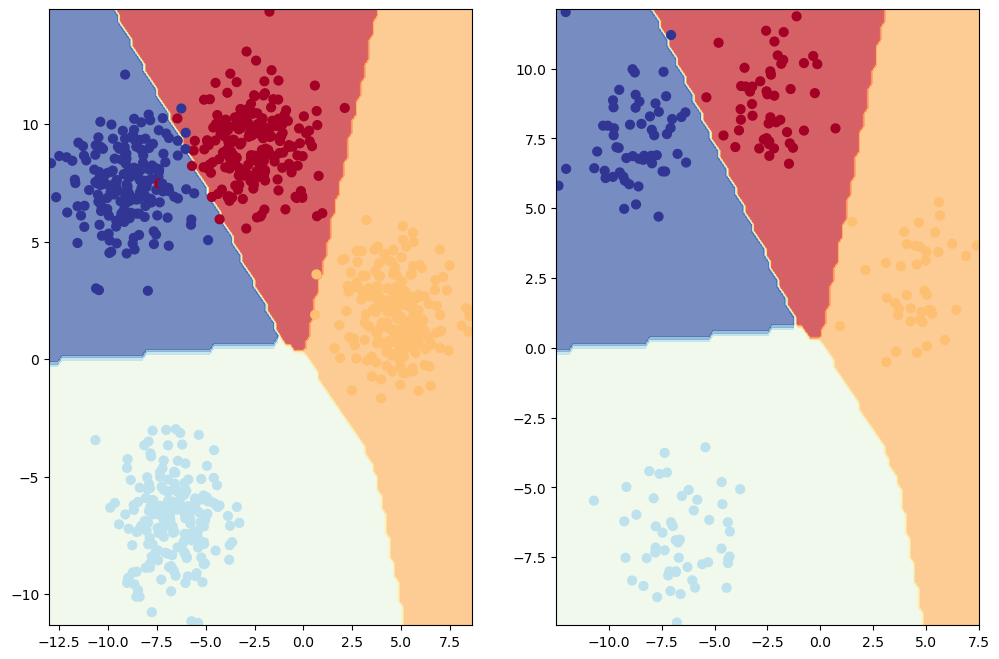

In [121]:
plt.figure(figsize = (12,8))
plt.subplot(1,2,1)
plot_decision_boundary(model2, X_blob_train, y_blob_train)
plt.subplot(1,2,2)
plot_decision_boundary(model2, X_blob_test, y_blob_test)